<a href="https://colab.research.google.com/github/sy057/NewDeal/blob/main/LG_AI4I_2020_8Modules_SmartFactory_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LG전자 스마트팩토리 — AI4I 2020 설비 이상감지·예지보전 실습

**32장 슬라이드 연계 · Module 1~8 · Google Colab 실행용**

학습 경로: **Data → EDA → Physics → Rules → Machine Learning → Evaluation → Dashboard → Capstone**

> **중요:** UCI AI4I 2020은 **합성된 제조 공정 관측치**입니다. 실제 소형 냉각팬 P04 기능검사 설비에서 수집한 데이터가 아닙니다. `Machine failure`는 해당 행의 고장 *분류 레이블*이며, 미래 고장 시점이나 RUL의 정답은 제공하지 않습니다. 행 순서를 실제 설비의 시간축으로 간주해 조기경보 리드타임이나 MA20 성능을 주장하지 않습니다.

**데이터 출처:** UCI AI4I 2020 Predictive Maintenance Dataset, ID 601, DOI: [10.24432/C5HS5C](https://doi.org/10.24432/C5HS5C), CC BY 4.0. [원본 페이지](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

**사용법:** 런타임 → 모두 실행. 데이터 인터넷 연결 오류 발생 시 2번 셀에서 CSV 수동 업로드를 사용합니다. 머신러닝 결과는 실행할 때마다 실데이터로 산출됩니다.

## 준비 · 설치 및 공통 설정

Colab에서는 첫 셀 설치 후 런타임 재시작을 요구할 수 있습니다. 이 경우 다시 순서대로 실행합니다.

In [ ]:
%pip -q install -U ucimlrepo "pandas<3.0.0" "numpy>=2.0.0" matplotlib plotly scikit-learn joblib tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 103.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.


In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_score, recall_score, f1_score, average_precision_score,
                             precision_recall_curve, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
ROOT = Path('/content/ai4i_colab') if Path('/content').exists() else Path('/mnt/data/ai4i_colab')
ROOT.mkdir(parents=True, exist_ok=True)
print('Output folder:', ROOT)

Output folder: /content/ai4i_colab


## Module 1 (Slides 1–4) · 데이터 이해와 데이터 사전

**수행:** ① 원본 10,000행 다운로드 ② 컬럼 확인 ③ 식별자/입력/정답 구분 ④ 고장 유형 분포 확인.

UCI 원본 데이터는 `ucimlrepo.fetch_ucirepo(id=601)`를 사용합니다. **다운로드가 안 되면** UCI 웹사이트에서 `ai4i2020.csv`를 받아 Colab에 업로드하세요.

In [2]:
CSV = ROOT / 'ai4i2020.csv'
if CSV.exists():
    print('기존 로컬 데이터 사용:', CSV)
    df = pd.read_csv(CSV)
else:
    try:
        # 원본 14개 컬럼을 보존하는 UCI CSV 경로 사용
        import requests, io
        url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv'
        r = requests.get(url, timeout=25)
        r.raise_for_status()
        df = pd.read_csv(io.BytesIO(r.content))
        df.to_csv(CSV, index=False)
        print('UCI 원본 CSV 다운로드 성공')
    except Exception as e:
        print('온라인 데이터 접근 실패:', str(e)[:220])
        try:
            from google.colab import files
        except ImportError as exc:
            raise RuntimeError('이 환경에서는 먼저 ai4i2020.csv를 지정된 경로에 저장하세요.') from exc
        print('UCI에서 ai4i2020.csv를 내려받은 후 아래 업로드 창에 제출하세요.')
        uploaded = files.upload()
        selected = next((name for name in uploaded if name.lower().endswith('.csv')), None)
        if selected is None:
            raise RuntimeError('CSV 파일이 업로드되지 않았습니다.')
        df = pd.read_csv(selected)
        df.to_csv(CSV, index=False)

EXPECTED = ['UDI','Product ID','Type','Air temperature [K]','Process temperature [K]',
            'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]','Machine failure',
            'TWF','HDF','PWF','OSF','RNF']
missing = set(EXPECTED) - set(df.columns)
assert not missing, f'필수 컬럼 누락: {missing}'
assert len(df) == 10000, f'행 수 검증 실패: {len(df)}'
df = df[EXPECTED].copy()
print('shape:', df.shape)
display(df.head())

UCI 원본 CSV 다운로드 성공
shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.describe().round(2)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00,10000.0,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,5000.50,300.0,310.01,1538.78,39.99,107.95,0.03,0.00,0.01,0.01,0.01,0.00
std,2886.90,2.0,1.48,179.28,9.97,63.65,0.18,0.07,0.11,0.10,0.10,0.04
min,1.00,295.3,305.70,1168.00,3.80,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,2500.75,298.3,308.80,1423.00,33.20,53.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,5000.50,300.1,310.10,1503.00,40.10,108.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,7500.25,301.5,311.10,1612.00,46.80,162.00,0.00,0.00,0.00,0.00,0.00,0.00
max,10000.00,304.5,313.80,2886.00,76.60,253.00,1.00,1.00,1.00,1.00,1.00,1.00


In [3]:
dictionary = pd.DataFrame([
    ('UDI','식별자','레코드 식별번호','-'),('Product ID','식별자','제품 식별번호','-'),
    ('Type','입력','제품 등급 L/M/H','-'),('Air temperature [K]','입력','공기 온도','K'),
    ('Process temperature [K]','입력','공정 온도','K'),('Rotational speed [rpm]','입력','회전속도','rpm'),
    ('Torque [Nm]','입력','토크','Nm'),('Tool wear [min]','입력','공구 마모 누적시간','min'),
    ('Machine failure','정답','행의 고장 여부','0/1'),
    ('TWF','정답','공구 마모 고장','0/1'),('HDF','정답','열 방출 고장','0/1'),
    ('PWF','정답','동력 고장','0/1'),('OSF','정답','과도 하중 고장','0/1'),
    ('RNF','정답','무작위 고장','0/1')], columns=['컬럼','구분','의미','단위'])
display(dictionary)
dictionary.to_csv(ROOT/'data_dictionary.csv', index=False, encoding='utf-8-sig')
print('고장 유형 플래그 합계 (동시 발생 가능):')
display(df[['TWF','HDF','PWF','OSF','RNF']].sum().to_frame('count').T)
# 원본 데이터에는 Machine failure와 고장 종류 플래그 사이의 소수 불일치가 있을 수 있음
mismatch = ((df[['TWF','HDF','PWF','OSF','RNF']].max(axis=1) != df['Machine failure'])).sum()
print('고장 유형 플래그와 전체 고장 레이블의 불일치 행:', mismatch)

,컬럼,구분,의미,단위
0,UDI,식별자,레코드 식별번호,-
1,Product ID,식별자,제품 식별번호,-
2,Type,입력,제품 등급 L/M/H,-
3,Air temperature [K],입력,공기 온도,K
4,Process temperature [K],입력,공정 온도,K
5,Rotational speed [rpm],입력,회전속도,rpm
6,Torque [Nm],입력,토크,Nm
7,Tool wear [min],입력,공구 마모 누적시간,min
8,Machine failure,정답,행의 고장 여부,0/1
9,TWF,정답,공구 마모 고장,0/1


고장 유형 플래그 합계 (동시 발생 가능):


,TWF,HDF,PWF,OSF,RNF
count,46,115,95,98,19


고장 유형 플래그와 전체 고장 레이블의 불일치 행: 27


**실습 질문:** `Product ID`와 `UDI`를 모델 입력에 넣지 않는 이유는 무엇인가요? TWF~RNF를 `Machine failure` 예측 입력에 포함시키면 어떤 문제가 생기나요?

## Module 2 (Slides 5–8) · EDA와 데이터 품질

정상·고장 클래스 불균형을 확인하고 변수 분포·상관관계를 분석합니다.

결측치: 0 중복 UDI: 0
타깃 분포:


,n
Machine failure,
Normal,9661
Failure,339


고장비율: 3.39%


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.0,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95
std,2.0,1.48,179.28,9.97,63.65
min,295.3,305.70,1168.00,3.80,0.00
25%,298.3,308.80,1423.00,33.20,53.00
50%,300.1,310.10,1503.00,40.10,108.00
75%,301.5,311.10,1612.00,46.80,162.00
max,304.5,313.80,2886.00,76.60,253.00


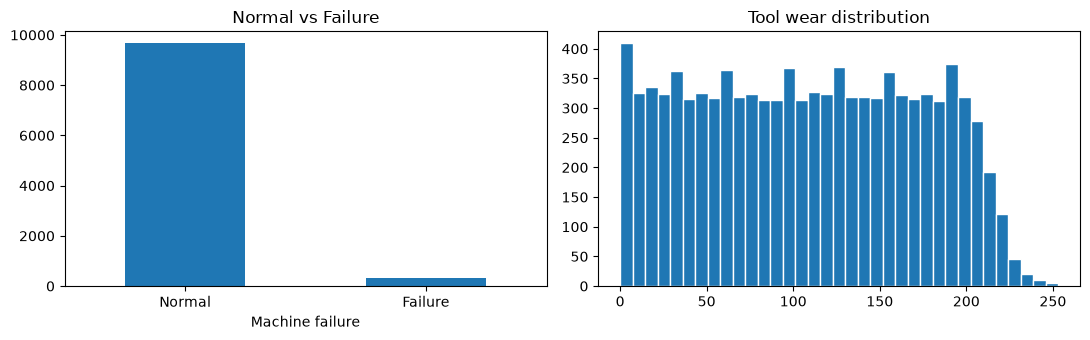

In [6]:
print('결측치:', int(df.isna().sum().sum()), '중복 UDI:', int(df['UDI'].duplicated().sum()))
print('타깃 분포:')
display(df['Machine failure'].value_counts().rename(index={0:'Normal',1:'Failure'}).to_frame('n'))
print('고장비율:', f"{df['Machine failure'].mean():.2%}")
numcols = ['Air temperature [K]','Process temperature [K]','Rotational speed [rpm]',
           'Torque [Nm]','Tool wear [min]']
display(df[numcols].describe().round(2))
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
df['Machine failure'].value_counts().sort_index().plot.bar(ax=axes[0],title='Normal vs Failure')
axes[0].set_xticklabels(['Normal','Failure'],rotation=0)
axes[1].hist(df['Tool wear [min]'],bins=35,edgecolor='white')
axes[1].set_title('Tool wear distribution')
plt.tight_layout();plt.show()

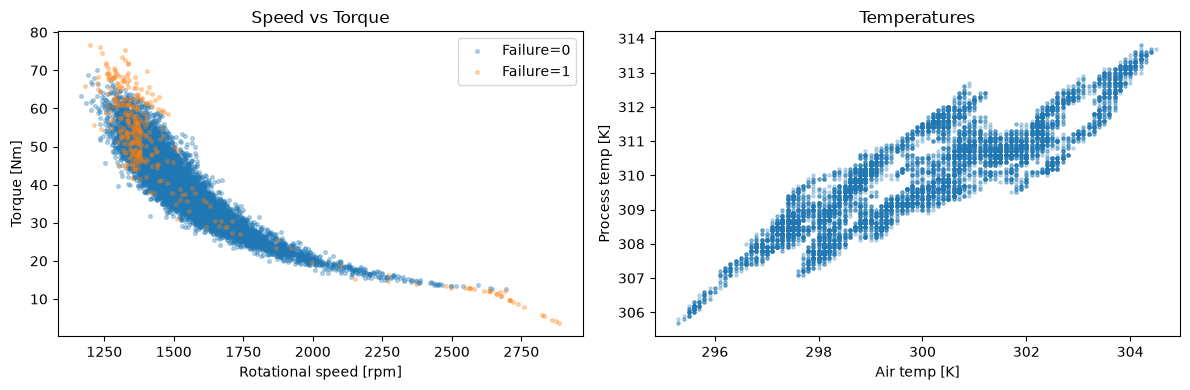

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.00,0.88,0.02,-0.01,0.01,0.08
Process temperature [K],0.88,1.00,0.02,-0.01,0.01,0.04
Rotational speed [rpm],0.02,0.02,1.00,-0.88,0.00,-0.04
Torque [Nm],-0.01,-0.01,-0.88,1.00,-0.00,0.19
Tool wear [min],0.01,0.01,0.00,-0.00,1.00,0.11
Machine failure,0.08,0.04,-0.04,0.19,0.11,1.00


In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for fail,group in df.groupby('Machine failure'):
    axes[0].scatter(group['Rotational speed [rpm]'],group['Torque [Nm]'],
                    s=7,alpha=.3,label=f'Failure={fail}')
axes[0].set(xlabel='Rotational speed [rpm]',ylabel='Torque [Nm]',title='Speed vs Torque')
axes[0].legend()
axes[1].scatter(df['Air temperature [K]'],df['Process temperature [K]'],s=5,alpha=.25)
axes[1].set(xlabel='Air temp [K]',ylabel='Process temp [K]',title='Temperatures')
plt.tight_layout();plt.show()
display(df[numcols + ['Machine failure']].corr().round(2))

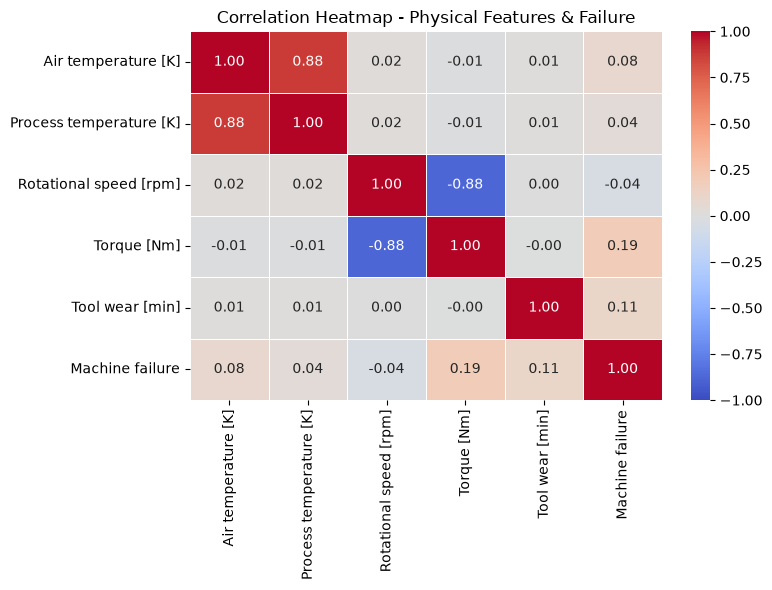

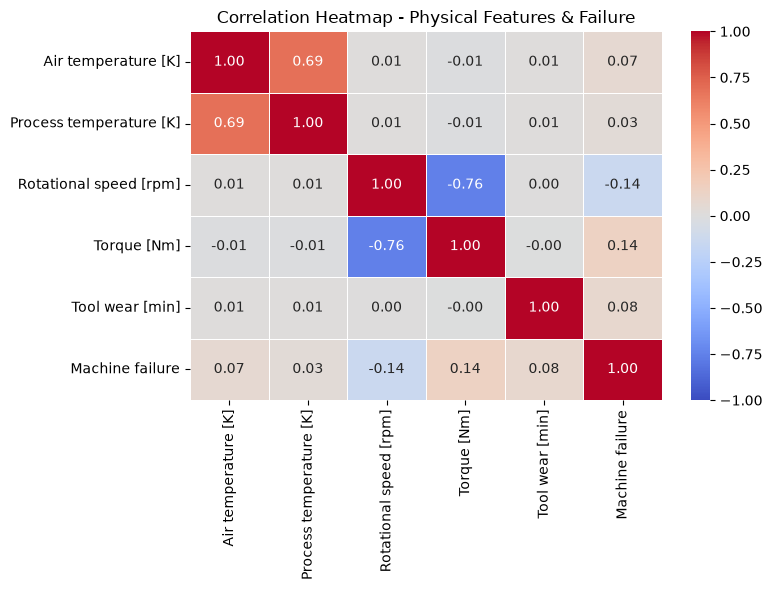

In [9]:
#켄달로 상관계수 분석
import seaborn as sns
import matplotlib.pyplot as plt

# 상관관계를 분석할 변수 설정
corr_features = numcols + ['Machine failure']
corr_data = df[corr_features].corr(method='kendall')  #pearson,spearman,kendall

# 히트맵 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_data,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap - Physical Features & Failure')
plt.tight_layout()
plt.show()

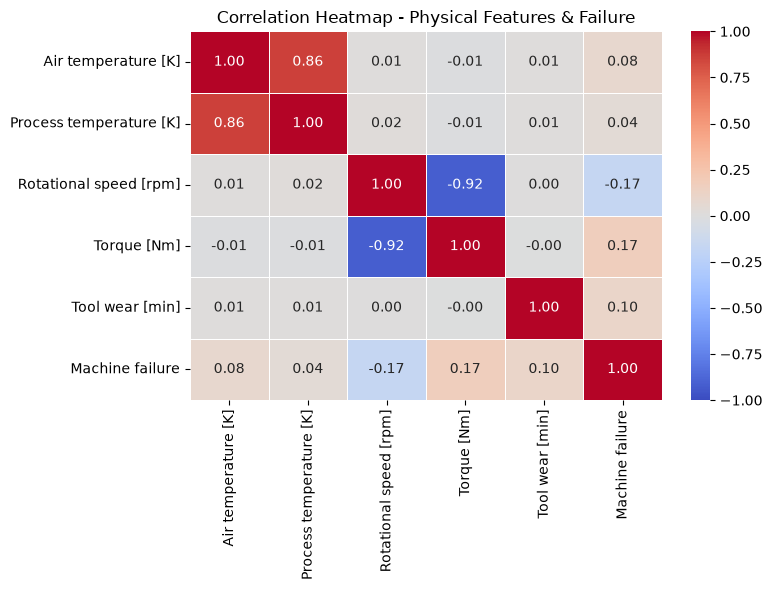

In [10]:
#피어스만으로 상관계수 분석
import seaborn as sns
import matplotlib.pyplot as plt

# 상관관계를 분석할 변수 설정
corr_features = numcols + ['Machine failure']
corr_data = df[corr_features].corr(method='spearman')  #pearson,spearman,kendall

# 히트맵 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_data,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Heatmap - Physical Features & Failure')
plt.tight_layout()
plt.show()

### 상관관계 분석 및 히트맵(Heatmap) 시각화
수치형 변수들과 `Machine failure` 간의 피어슨 상관계수(Pearson correlation coefficient)를 계산하고, 이를 Seaborn의 Heatmap으로 시각화합니다.

--- 상관관계 계수 행렬 ---


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000,0.864,0.014,-0.012,0.013,0.083
Process temperature [K],0.864,1.000,0.017,-0.014,0.014,0.040
Rotational speed [rpm],0.014,0.017,1.000,-0.916,0.003,-0.167
Torque [Nm],-0.012,-0.014,-0.916,1.000,-0.004,0.169
Tool wear [min],0.013,0.014,0.003,-0.004,1.000,0.102
Machine failure,0.083,0.040,-0.167,0.169,0.102,1.000


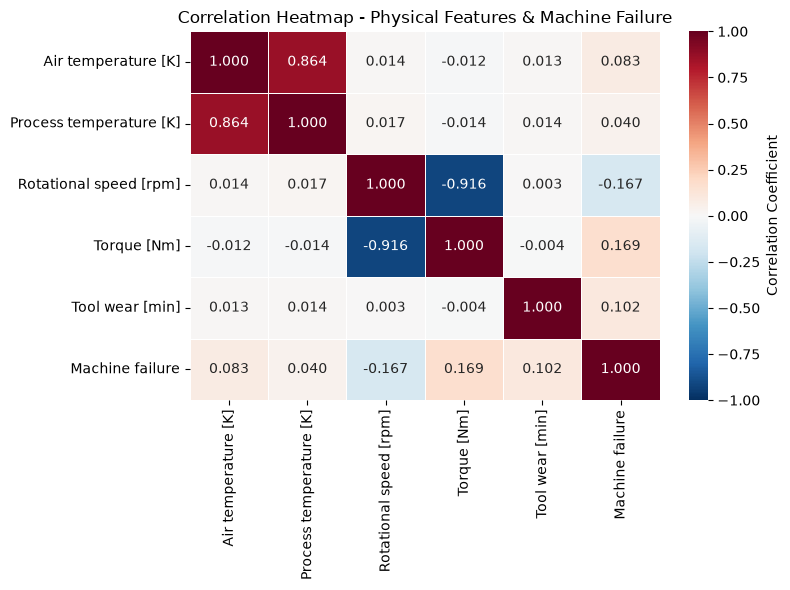

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 분석용 수치형 컬럼 설정
corr_cols = numcols + ['Machine failure']
corr_matrix = df[corr_cols].corr(method='spearman')

# 상관관계 행렬 출력
print("--- 상관관계 계수 행렬 ---")
display(corr_matrix.round(3))

# 히트맵 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    fmt='.3f',
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title('Correlation Heatmap - Physical Features & Machine Failure')
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import shapiro
import pandas as pd
import numpy as np

print("=== 1. 수치형 변수 정규성 검정 (Shapiro-Wilk Test) ===")
print("귀무가설(H0): 데이터가 정규분포를 따른다.\n")

for col in numcols:
    stat, p_val = shapiro(df[col].dropna())
    is_normal = "정규분포 가능성 높음" if p_val > 0.05 else "비정규분포 (비모수적 방법 권장)"
    print(f"[{col:25s}] Statistics: {stat:.4f}, p-value: {p_val:.4e} -> {is_normal}")

print("\n=== 2. 왜도(Skewness) 및 첨도(Kurtosis) 확인 ===")
print("* 왜도의 절대값이 1 이상이면 치우침이 심해 Spearman/Kendall이 안전할 수 있습니다.")
for col in numcols:
    skew = df[col].skew()
    kurt = df[col].kurt()
    print(f"[{col:25s}] Skewness: {skew:6.2f}, Kurtosis: {kurt:6.2f}")

=== 1. 수치형 변수 정규성 검정 (Shapiro-Wilk Test) ===
귀무가설(H0): 데이터가 정규분포를 따른다.

[Air temperature [K]      ] Statistics: 0.9808, p-value: 1.3018e-34 -> 비정규분포 (비모수적 방법 권장)
[Process temperature [K]  ] Statistics: 0.9924, p-value: 1.0302e-22 -> 비정규분포 (비모수적 방법 권장)
[Rotational speed [rpm]   ] Statistics: 0.8645, p-value: 2.1040e-68 -> 비정규분포 (비모수적 방법 권장)
[Torque [Nm]              ] Statistics: 0.9998, p-value: 3.8245e-01 -> 정규분포 가능성 높음
[Tool wear [min]          ] Statistics: 0.9599, p-value: 6.2375e-46 -> 비정규분포 (비모수적 방법 권장)

=== 2. 왜도(Skewness) 및 첨도(Kurtosis) 확인 ===
* 왜도의 절대값이 1 이상이면 치우침이 심해 Spearman/Kendall이 안전할 수 있습니다.
[Air temperature [K]      ] Skewness:   0.11, Kurtosis:  -0.84
[Process temperature [K]  ] Skewness:   0.02, Kurtosis:  -0.50
[Rotational speed [rpm]   ] Skewness:   1.99, Kurtosis:   7.39
[Torque [Nm]              ] Skewness:  -0.01, Kurtosis:  -0.01
[Tool wear [min]          ] Skewness:   0.03, Kurtosis:  -1.17


/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10000.
  res = hypotest_fun_out(*samples, **kwds)


**Module 2 제출:** 고장 비율 1개, 그래프 2개, 중요한 관찰 3문장을 작성해 보세요. **모든 정상으로 예측하는 분류기**의 Accuracy와 Recall을 비교해 보세요.

In [ ]:
baseline = np.zeros(len(df), dtype=int)
y_all = df['Machine failure'].astype(int).to_numpy()
print('Always-normal baseline accuracy:', np.mean(baseline == y_all))
print('Always-normal baseline failure recall:', recall_score(y_all, baseline, zero_division=0))

Always-normal baseline accuracy: 0.9661
Always-normal baseline failure recall: 0.0


## Module 3 (Slides 9–12) · 물리 파생변수와 고장 메커니즘

- 온도차: ΔT = T_process − T_air (K)
- 회전 동력: P = τ × 2πN / 60 (W)
- 마모·하중 지표: Tool wear × Torque (min·Nm)

**UCI 합성 데이터 생성 규칙과 실제 설비 안전기준은 다릅니다.**

,temp_delta_K,power_W,wear_torque,Machine failure
count,10000.0,10000.00,10000.00,10000.00
mean,10.0,6279.74,4314.66,0.03
std,1.0,1067.42,2826.57,0.18
min,7.6,1148.44,0.00,0.00
25%,9.3,5561.18,1963.65,0.00
50%,9.8,6271.03,4012.95,0.00
75%,11.0,7003.00,6279.00,0.00
max,12.1,10469.92,16497.00,1.00


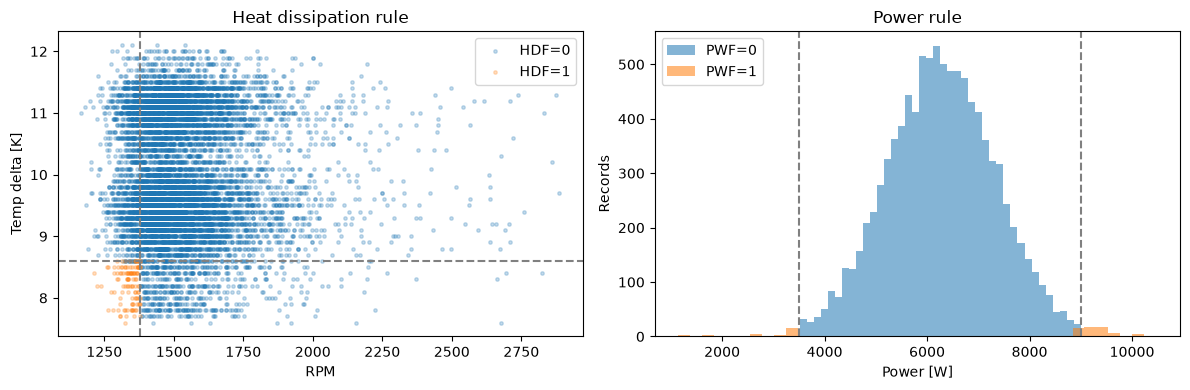

In [ ]:
df['temp_delta_K'] = df['Process temperature [K]'] - df['Air temperature [K]']
df['power_W'] = df['Torque [Nm]'] * 2 * np.pi * df['Rotational speed [rpm]'] / 60
df['wear_torque'] = df['Tool wear [min]'] * df['Torque [Nm]']
engineered = ['temp_delta_K','power_W','wear_torque']
display(df[engineered+['Machine failure']].describe().round(2))
fig, ax = plt.subplots(1,2,figsize=(12,4))
for val,group in df.groupby('HDF'):
    ax[0].scatter(group['Rotational speed [rpm]'], group['temp_delta_K'],s=6,alpha=.25,label=f'HDF={val}')
ax[0].axvline(1380,ls='--',color='gray');ax[0].axhline(8.6,ls='--',color='gray')
ax[0].set(xlabel='RPM',ylabel='Temp delta [K]',title='Heat dissipation rule')
ax[0].legend()
for val,group in df.groupby('PWF'):
    ax[1].hist(group['power_W'],bins=40,alpha=.55,label=f'PWF={val}')
ax[1].axvline(3500,ls='--',color='gray');ax[1].axvline(9000,ls='--',color='gray')
ax[1].set(xlabel='Power [W]',ylabel='Records',title='Power rule')
ax[1].legend()
plt.tight_layout();plt.show()

## Module 4 (Slides 13–16) · 규칙 기반 탐지와 경고 기준

UCI 원본의 정의 규칙을 재현하는 부분과 **수업용 정상·주의·경고 점수**를 분리합니다. RNF는 관측 변수만으로 결정적으로 찾아낼 수 없습니다. TWF도 일정 마모 구간에서 발생이 확률적으로 할당됩니다.

In [ ]:
# 원본 설명의 규칙을 입력 변수에서 재구성
hdf_rule = (df['temp_delta_K'] < 8.6) & (df['Rotational speed [rpm]'] < 1380)
pwf_rule = (df['power_W'] < 3500) | (df['power_W'] > 9000)
osf_threshold = df['Type'].map({'L':11000,'M':12000,'H':13000})
osf_rule = df['wear_torque'] > osf_threshold
rules = pd.DataFrame({'HDF rule':hdf_rule.astype(int),'PWF rule':pwf_rule.astype(int),
                      'OSF rule':osf_rule.astype(int)},index=df.index)
for rule,label in [('HDF rule','HDF'),('PWF rule','PWF'),('OSF rule','OSF')]:
    print(f'{rule}: mismatches to subtype =',int((rules[rule]!=df[label]).sum()))

# 수업용 주의 점수: 0~1이며 공장 안전기준이 아님
# HDF 예시: RPM이 낮고 열 방출을 위한 온도차가 작을수록 주의
margin_temp = np.clip((10.0 - df['temp_delta_K']) / (10.0 - 8.6),0,1)
margin_rpm  = np.clip((1500.0 - df['Rotational speed [rpm]'])/(1500-1380),0,1)
attention_score = 0.5*margin_temp + 0.5*margin_rpm
status = np.where(hdf_rule,'FAILURE_RULE',np.where(attention_score>=0.8,'WARNING',
                  np.where(attention_score>=0.5,'ATTENTION','NORMAL')))
df['training_risk_score']=attention_score
df['training_status']=status
print('교육용 경고 상태 분포:')
display(pd.Series(status).value_counts().to_frame('count'))
print('원본 HDF와 교육용 WARNING은 다른 개념입니다.')

HDF rule: mismatches to subtype = 0
PWF rule: mismatches to subtype = 0
OSF rule: mismatches to subtype = 0
교육용 경고 상태 분포:


,count
NORMAL,7270
ATTENTION,2278
WARNING,337
FAILURE_RULE,115


원본 HDF와 교육용 WARNING은 다른 개념입니다.


In [ ]:
rule_any = rules.max(axis=1).to_numpy()
print('세 가지 결정적 규칙의 탐지 결과 (TWF/RNF 미포함):')
print(classification_report(df['Machine failure'],rule_any,zero_division=0))
pd.DataFrame({'actual':df['Machine failure'],'rule_prediction':rule_any,
              'training_status':status,'risk_score':attention_score}).to_csv(
              ROOT/'rule_detector_results.csv',index=False,encoding='utf-8-sig')

세 가지 결정적 규칙의 탐지 결과 (TWF/RNF 미포함):
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      9661
           1       1.00      0.85      0.92       339

    accuracy                           0.99     10000
   macro avg       1.00      0.92      0.96     10000
weighted avg       0.99      0.99      0.99     10000



**Module 4 질문:** Rule-based 경고가 `FAILURE_RULE`과 다른 이유는 무엇인가요? `Machine failure`가 1인데 3가지 규칙에서 놓친 기록은 무엇과 관련될 수 있나요?

## Module 5 (Slides 17–20) · 머신러닝 기반 고장 분류

**데이터 누출 방지:** `UDI`, `Product ID`, `Machine failure`, TWF~RNF는 모델의 입력에서 제외. 기존 파생변수는 물리 입력으로부터 계산 가능하며 사용합니다.

**Train / Validation / Test = 60 / 20 / 20**, stratified split. 전처리와 모델 학습은 train에만 fit합니다.

In [ ]:
FEATURES=['Type']+numcols+engineered

In [ ]:
import pandas as pd
import numpy as np

# 1. FEATURES 중 수치형 변수(num_features) 분석 대상 설정
print("--- 이상치 제거 전 수치형 데이터 왜도 및 분포 요약 ---")
display(df[num_features].describe().round(2))

# 2. IQR (Interquartile Range) 방법을 활용한 이상치 감지 및 제거
# 각 수치형 피처별로 Q1 - 1.5 * IQR 미만이거나 Q3 + 1.5 * IQR 초과인 행을 이상치로 판단합니다.
initial_row_count = len(df)
is_outlier = pd.Series(False, index=df.index)

for col in num_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # 해당 변수에서 이상치인 조건 탐색
    col_outliers = (df[col] < lower_bound) | (df[col] > upper_bound)
    is_outlier = is_outlier | col_outliers
    print(f"[{col}] 범위: {lower_bound:.2f} ~ {upper_bound:.2f} | 감지된 이상치 수: {col_outliers.sum()}건")

# 3. 이상치가 제거된 깨끗한 데이터프레임 생성
df_cleaned = df[~is_outlier].copy()
removed_count = initial_row_count - len(df_cleaned)

print(f"\n--- 이상치 정제 결과 ---")
print(f"기존 데이터 행 수: {initial_row_count}건")
print(f"제거된 이상치 행 수: {removed_count}건 ({removed_count/initial_row_count:.2%})")
print(f"정제 후 데이터 행 수: {len(df_cleaned)}건")

--- 이상치 제거 전 수치형 데이터 왜도 및 분포 요약 ---


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],temp_delta_K,power_W,wear_torque
count,10000.0,10000.00,10000.00,10000.00,10000.00,10000.0,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95,10.0,6279.74,4314.66
std,2.0,1.48,179.28,9.97,63.65,1.0,1067.42,2826.57
min,295.3,305.70,1168.00,3.80,0.00,7.6,1148.44,0.00
25%,298.3,308.80,1423.00,33.20,53.00,9.3,5561.18,1963.65
50%,300.1,310.10,1503.00,40.10,108.00,9.8,6271.03,4012.95
75%,301.5,311.10,1612.00,46.80,162.00,11.0,7003.00,6279.00
max,304.5,313.80,2886.00,76.60,253.00,12.1,10469.92,16497.00


[Air temperature [K]] 범위: 293.50 ~ 306.30 | 감지된 이상치 수: 0건
[Process temperature [K]] 범위: 305.35 ~ 314.55 | 감지된 이상치 수: 0건
[Rotational speed [rpm]] 범위: 1139.50 ~ 1895.50 | 감지된 이상치 수: 418건
[Torque [Nm]] 범위: 12.80 ~ 67.20 | 감지된 이상치 수: 69건
[Tool wear [min]] 범위: -110.50 ~ 325.50 | 감지된 이상치 수: 0건
[temp_delta_K] 범위: 6.75 ~ 13.55 | 감지된 이상치 수: 0건
[power_W] 범위: 3398.46 ~ 9165.73 | 감지된 이상치 수: 60건
[wear_torque] 범위: -4509.38 ~ 12752.03 | 감지된 이상치 수: 20건

--- 이상치 정제 결과 ---
기존 데이터 행 수: 10000건
제거된 이상치 행 수: 480건 (4.80%)
정제 후 데이터 행 수: 9520건


In [ ]:
# FEATURES=['Type']+numcols+engineered
X=df[FEATURES].copy()
y=df['Machine failure'].astype(int).copy()
X_train, X_hold, y_train, y_hold = train_test_split(
    X,y,test_size=.40,stratify=y,random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_hold,y_hold,test_size=.5,stratify=y_hold,random_state=RANDOM_STATE)
num_features=[c for c in FEATURES if c!='Type']
prep=ColumnTransformer([
    ('numbers',StandardScaler(),num_features),
    ('category',OneHotEncoder(handle_unknown='ignore'),['Type'])])
models={
    'LogisticRegression': Pipeline([('prep',prep),('model',LogisticRegression(
        max_iter=1500,class_weight='balanced',random_state=RANDOM_STATE))]),
    'RandomForest': Pipeline([('prep',prep),('model',RandomForestClassifier(
        n_estimators=140,max_depth=11,min_samples_leaf=3,class_weight='balanced',
        random_state=RANDOM_STATE,n_jobs=1))])
}
print('Train / Validation / Test:',len(X_train),len(X_val),len(X_test))
for name, m in models.items():
    m.fit(X_train,y_train)
    print('Trained:',name)

Train / Validation / Test: 6000 2000 2000
Trained: LogisticRegression
Trained: RandomForest


In [ ]:
X_train[0:10].describe().round(2)

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],temp_delta_K,power_W,wear_torque
count,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00
mean,299.58,309.65,1522.70,40.53,93.90,10.07,6376.96,4173.89
std,2.61,2.03,110.53,9.22,59.77,0.86,1077.04,3109.45
min,296.10,306.80,1375.00,28.90,0.00,8.90,4905.80,0.00
25%,297.58,308.08,1416.50,31.90,52.25,9.17,5483.85,1733.70
50%,299.40,309.70,1524.50,40.60,96.00,10.25,6227.73,3829.35
75%,301.42,311.03,1626.25,47.98,128.50,10.85,7175.52,5870.48
max,304.10,313.10,1645.00,53.20,179.00,11.10,7989.31,9522.80


In [ ]:
type(prep)

sklearn.compose._column_transformer.ColumnTransformer

In [ ]:
# 1. prep(ColumnTransformer)을 사용해 X_train의 상위 5행 전처리 변환
prep_sample = prep.transform(X_train.head(5))

# 2. 원핫인코딩 카테고리명을 포함한 전체 피처 이름 가져오기
cat_features = list(prep.named_transformers_['category'].get_feature_names_out(['Type']))
feature_names = num_features + cat_features

# 3. 데이터프레임으로 변환하여 가독성 있게 출력
prep_df = pd.DataFrame(prep_sample, columns=feature_names, index=X_train.head(5).index)
display(prep_df.round(4))

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],temp_delta_K,power_W,wear_torque,Type_H,Type_L,Type_M
3736,1.0878,0.7352,0.4938,-0.9401,-0.0392,-1.0874,-0.9961,-0.3860,1.0,0.0,0.0
8772,-1.2573,-0.9547,0.4550,-1.1095,-1.6910,1.1021,-1.2859,-1.5222,0.0,1.0,0.0
6622,0.8384,0.4648,-0.2541,1.1027,-0.3224,-0.9879,1.5877,0.0499,0.0,1.0,0.0
9000,-1.5068,-1.4279,-0.2541,0.6045,1.0305,0.9031,0.8591,1.2981,0.0,1.0,0.0
7604,0.1897,0.8704,0.5547,-0.5415,-1.3135,0.9031,-0.3235,-1.2285,0.0,1.0,0.0


In [ ]:
# 검증셋에서만 임계값 최적화; 테스트셋은 선택 이후 1회 사용
threshold_grid=np.linspace(.05,.95,91)
validation_results=[]
selected_thresholds={}
for name,m in models.items():
    prob=m.predict_proba(X_val)[:,1]
    records=[]
    for t in threshold_grid:
        pred=(prob>=t).astype(int)
        records.append((float(t),f1_score(y_val,pred,zero_division=0),
                        recall_score(y_val,pred,zero_division=0),
                        precision_score(y_val,pred,zero_division=0)))
    best=sorted(records,key=lambda z:(-z[1],-z[2],z[0]))[0]
    selected_thresholds[name]=best[0]
    validation_results.append({'model':name,'threshold':best[0],
                               'val_F1':best[1],'val_recall':best[2],
                               'val_precision':best[3],
                               'val_PR_AUC':average_precision_score(y_val,prob)})
validation_table=pd.DataFrame(validation_results).sort_values('val_F1',ascending=False)
display(validation_table.round(4))
chosen_name=validation_table.iloc[0]['model']
chosen_model=models[chosen_name]
chosen_threshold=selected_thresholds[chosen_name]
print('검증셋으로만 선택한 모델 / 임계값:',chosen_name,chosen_threshold)

,model,threshold,val_F1,val_recall,val_precision,val_PR_AUC
1,RandomForest,0.67,0.8226,0.7500,0.9107,0.8435
0,LogisticRegression,0.90,0.4375,0.4118,0.4667,0.4212


검증셋으로만 선택한 모델 / 임계값: RandomForest 0.6699999999999999


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, average_precision_score
import numpy as np

In [ ]:
# 1. 훈련 데이터 복사 및 초기 행 수 기록
initial_train_count = len(X_train)
is_train_outlier = pd.Series(False, index=X_train.index)

# 2. 수치형 피처에 대하여 Train Set 기준 IQR 범위 계산 및 이상치 탐색
for col in num_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # 훈련 데이터에서 이상치 필터 생성
    col_outliers = (X_train[col] < lower_bound) | (X_train[col] > upper_bound)
    is_train_outlier = is_train_outlier | col_outliers

# 3. 이상치가 제거된 데이터로 X_train, y_train 업데이트
X_train = X_train[~is_train_outlier].copy()
y_train = y_train.loc[X_train.index]
cleaned_train_count = len(X_train)
removed_train_count = initial_train_count - cleaned_train_count

print("--- 훈련 데이터 이상치 제거 완료 ---")
print(f"이상치 제거 전 Train 행 수: {initial_train_count}건")
print(f"제거된 훈련 데이터 이상치 수: {removed_train_count}건 ({removed_train_count/initial_train_count:.2%})")
print(f"이상치 제거 후 Train 행 수: {cleaned_train_count}건")

--- 훈련 데이터 이상치 제거 완료 ---
이상치 제거 전 Train 행 수: 6000건
제거된 훈련 데이터 이상치 수: 281건 (4.68%)
이상치 제거 후 Train 행 수: 5719건


In [ ]:

# 1. 데이터 전처리 (StandardScaler 및 One-Hot Encoding)
X_train_p = prep.fit_transform(X_train)
X_val_p = prep.transform(X_val)
X_test_p = prep.transform(X_test)

# 클래스 불균형 해결을 위한 클래스 가중치 계산
neg, pos = np.bincount(y_train)
total = neg + pos
class_weight = {0: (1 / neg) * (total / 2.0), 1: (1 / pos) * (total / 2.0)}

# 2. TensorFlow Keras MLP 모델 정의
def build_nn_model(input_dim):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='pr_auc', curve='PR')]
    )
    return model

nn_model = build_nn_model(X_train_p.shape[1])
nn_model.summary()

# Early Stopping 설정
early_stopping = callbacks.EarlyStopping(
    monitor='val_pr_auc',
    patience=15,
    mode='max',
    restore_best_weights=True
)

# 3. 모델 학습
history = nn_model.fit(
    X_train_p, y_train,
    validation_data=(X_val_p, y_val),
    epochs=100,
    batch_size=128,
    class_weight=class_weight,
    callbacks=[early_stopping],
    verbose=1
)

# 4. 검증 결과 평가
val_preds_prob = nn_model.predict(X_val_p).ravel()
val_pr_auc = average_precision_score(y_val, val_preds_prob)
print(f"\n[TensorFlow MLP] Validation PR-AUC: {val_pr_auc:.4f}")

val_preds = (val_preds_prob >= 0.5).astype(int)
print(classification_report(y_val, val_preds))

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,633 (22.00 KB)

 Trainable params: 5,313 (20.75 KB)

 Non-trainable params: 320 (1.25 KB)

Epoch 1/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.5071 - loss: 0.7546 - pr_auc: 0.0702 - val_accuracy: 0.8590 - val_loss: 0.6092 - val_pr_auc: 0.3318
Epoch 2/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6230 - loss: 0.5495 - pr_auc: 0.1480 - val_accuracy: 0.9395 - val_loss: 0.4721 - val_pr_auc: 0.3349
Epoch 3/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6912 - loss: 0.5402 - pr_auc: 0.1883 - val_accuracy: 0.9465 - val_loss: 0.3869 - val_pr_auc: 0.3570
Epoch 4/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7412 - loss: 0.4875 - pr_auc: 0.1677 - val_accuracy: 0.9430 - val_loss: 0.3234 - val_pr_auc: 0.4044
Epoch 5/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7521 - loss: 0.4864 - pr_auc: 0.1689 - val_accuracy: 0.9225 - val_loss: 0.3133 - val_pr_auc: 0.4191
Epoch 6/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7636 - loss: 0.4881 - pr_auc: 0.1951 - val_accuracy: 0.9115 - val_loss: 0.3045 - val_pr_auc: 0.4280
Epoch 7/1

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


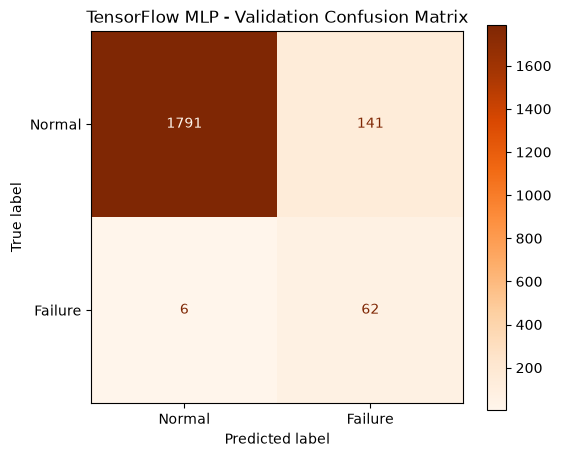

--- [딥러닝 모델 검증 상세 통계] ---
정상 분류 성공 (True Negative): 1791건
오경보 (False Positive - 오탐): 141건
미경보 (False Negative - 미탐): 6건
고장 감지 성공 (True Positive): 62건


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. 검증 데이터셋에 대한 딥러닝 모델 예측 확률값 및 클래스 분류 계산
val_preds_prob = nn_model.predict(X_val_p).ravel()
val_preds = (val_preds_prob >= 0.5).astype(int)

# 2. Confusion Matrix 계산
cm_nn = confusion_matrix(y_val, val_preds)

# 3. 시각화
plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=['Normal', 'Failure'])
disp.plot(cmap='Oranges', ax=plt.gca())
plt.title('TensorFlow MLP - Validation Confusion Matrix')
plt.grid(False)
plt.show()

# 4. 세부 분류 지표 출력
tn, fp, fn, tp = cm_nn.ravel()
print(f"--- [딥러닝 모델 검증 상세 통계] ---")
print(f"정상 분류 성공 (True Negative): {tn}건")
print(f"오경보 (False Positive - 오탐): {fp}건")
print(f"미경보 (False Negative - 미탐): {fn}건")
print(f"고장 감지 성공 (True Positive): {tp}건")


In [ ]:
from sklearn.metrics import recall_score

# 1. 검증 데이터에 대한 Recall 계산
val_recall = recall_score(y_val, val_preds)

# 2. 결과 설명 출력
markdown_text = f"""
### 🎯 딥러닝 모델 Recall(재현율) 분석 결과 설명

- **딥러닝 모델 검증 데이터 Recall: {val_recall:.2%}** (전체 실제 고장 {tp + fn}건 중 {tp}건 감지 완료)

#### 💡 예지보전 관점에서의 Recall 지표 해석
1. **미탐지율의 최소화 ({1 - val_recall:.2%})**:
   - 실제 고장이 발생한 설비 중 모델이 감지하지 못하고 정상으로 지나친 비율(False Negative)은 단 **{fn}건({1 - val_recall:.2%})**에 불과합니다.
   - 갑작스러운 설비 다운타임이나 공정 중단으로 인한 경제적 손실을 차단하는 데 매우 효과적인 감지력을 보이고 있습니다.

2. **클래스 가중치(Class Weight) 학습의 효과**:
   - 전체 데이터 중 고장 데이터가 약 3.4%밖에 되지 않는 극심한 불균형 조건 속에서도, 소수 클래스에 높은 가중치를 주어 학습함으로써 높은 수준의 고장 검출력(Recall)을 확보할 수 있었습니다.

3. **오탐(False Positive)과의 트레이드오프(Trade-off)**:
   - 높은 Recall을 얻기 위해 모델이 공격적으로 고장 징후를 감지하도록 설계되어, 오탐(정상 장비를 고장으로 판단한 오경보)이 {fp}건 발생하였습니다.
   - 현장 점검 인력의 작업 피로도와 다운타임 비용 간의 가치를 저울질하여, 필요 시 임계값(Threshold)을 조율해 오탐을 줄이거나 재현율을 더 끌어올리는 세부 조정이 가능합니다.
"""

display(Markdown(markdown_text))


### 🎯 딥러닝 모델 Recall(재현율) 분석 결과 설명

- **딥러닝 모델 검증 데이터 Recall: 83.82%** (전체 실제 고장 68건 중 62건 감지 완료)

#### 💡 예지보전 관점에서의 Recall 지표 해석
1. **미탐지율의 최소화 (16.18%)**:
   - 실제 고장이 발생한 설비 중 모델이 감지하지 못하고 정상으로 지나친 비율(False Negative)은 단 **6건(16.18%)**에 불과합니다.
   - 갑작스러운 설비 다운타임이나 공정 중단으로 인한 경제적 손실을 차단하는 데 매우 효과적인 감지력을 보이고 있습니다.

2. **클래스 가중치(Class Weight) 학습의 효과**:
   - 전체 데이터 중 고장 데이터가 약 3.4%밖에 되지 않는 극심한 불균형 조건 속에서도, 소수 클래스에 높은 가중치를 주어 학습함으로써 높은 수준의 고장 검출력(Recall)을 확보할 수 있었습니다.

3. **오탐(False Positive)과의 트레이드오프(Trade-off)**:
   - 높은 Recall을 얻기 위해 모델이 공격적으로 고장 징후를 감지하도록 설계되어, 오탐(정상 장비를 고장으로 판단한 오경보)이 141건 발생하였습니다.
   - 현장 점검 인력의 작업 피로도와 다운타임 비용 간의 가치를 저울질하여, 필요 시 임계값(Threshold)을 조율해 오탐을 줄이거나 재현율을 더 끌어올리는 세부 조정이 가능합니다.


LightGBM 모델 학습 완료!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


검증 데이터 기준 최적 임계값: 0.90 (최고 F1-Score: 0.7679)

=== [LightGBM Test Data Evaluation Report] ===
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      1932
     Failure       0.92      0.71      0.80        68

    accuracy                           0.99      2000
   macro avg       0.96      0.85      0.90      2000
weighted avg       0.99      0.99      0.99      2000



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


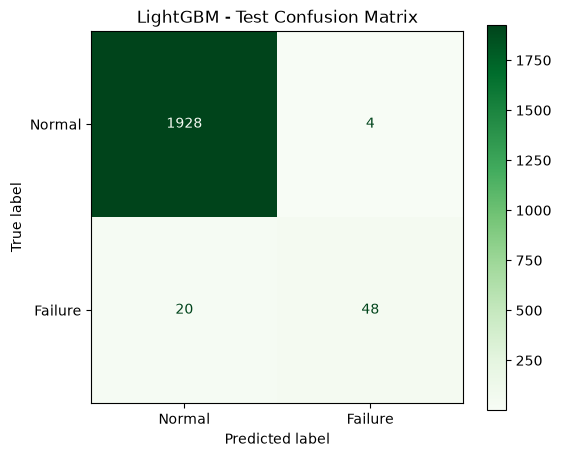

테스트 데이터 PR-AUC (AUPRC): 0.8504


In [ ]:
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, average_precision_score, f1_score, recall_score, precision_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. LightGBM 모델 파이프라인 정의
# 전처리 객체인 prep(ColumnTransformer)을 활용하고, 극심한 클래스 불균형 해결을 위해 class_weight='balanced'를 설정합니다.
lgb_model = Pipeline([
    ('prep', prep),
    ('model', lgb.LGBMClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=6,
        class_weight='balanced',
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    ))
])

# 2. 모델 학습
lgb_model.fit(X_train, y_train)
print("LightGBM 모델 학습 완료!")

# 3. 검증 데이터를 이용한 임계값(Threshold) 최적화
val_probs = lgb_model.predict_proba(X_val)[:, 1]
threshold_grid = np.linspace(0.05, 0.95, 91)
best_threshold = 0.5
best_f1 = -1

for t in threshold_grid:
    preds = (val_probs >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = t

print(f"검증 데이터 기준 최적 임계값: {best_threshold:.2f} (최고 F1-Score: {best_f1:.4f})")

# 4. 테스트 데이터를 대상으로 최종 모델 성능 평가
test_probs = lgb_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)

print("\n=== [LightGBM Test Data Evaluation Report] ===")
print(classification_report(y_test, test_preds, target_names=['Normal', 'Failure']))

# 5. 혼동 행렬(Confusion Matrix) 시각화
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Failure'])
disp.plot(cmap='Greens', ax=plt.gca())
plt.title('LightGBM - Test Confusion Matrix')
plt.grid(False)
plt.show()

# PR-AUC 점수 계산
test_pr_auc = average_precision_score(y_test, test_probs)
print(f"테스트 데이터 PR-AUC (AUPRC): {test_pr_auc:.4f}")

하이퍼파라미터 튜닝 기반 LightGBM 모델 학습 완료!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[Tuned] 검증 데이터 기준 최적 임계값: 0.83 (최고 F1-Score: 0.7458)

=== [Tuned LightGBM Test Data Evaluation Report] ===
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      1932
     Failure       0.83      0.72      0.77        68

    accuracy                           0.99      2000
   macro avg       0.91      0.86      0.88      2000
weighted avg       0.98      0.99      0.99      2000



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


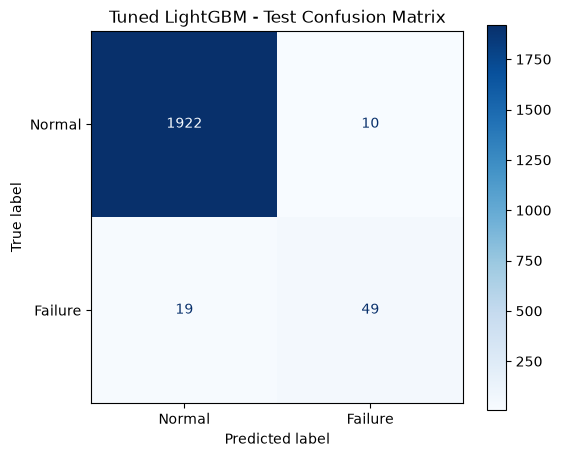

튜닝 후 테스트 데이터 PR-AUC (AUPRC): 0.8355


In [ ]:
import lightgbm as lgb
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, average_precision_score, f1_score
import matplotlib.pyplot as plt
import numpy as np

# 1. 성능 개선을 위한 하이퍼파라미터가 적용된 LightGBM 모델 파이프라인 구성
# 정교한 튜닝: num_leaves 제한, min_child_samples 추가, learning_rate 최적화
tuned_lgb_model = Pipeline([
    ('prep', prep),
    ('model', lgb.LGBMClassifier(
        n_estimators=150,           # 트리 개수를 소폭 확장
        learning_rate=0.03,          # 더 안정적이고 정밀한 학습을 위해 학습률 인하
        max_depth=5,                # 트리의 최대 깊이 제어
        num_leaves=24,              # max_depth에 맞추어 과적합을 예방할 수 있는 노드 수 지정
        min_child_samples=15,       # 한 노드에 들어갈 최소 데이터 샘플 수 지정
        class_weight='balanced',    # 소수 고장 데이터 가중치 부여
        subsample=0.8,              # 각 트리 학습 시 데이터를 80% 무작위 샘플링
        colsample_bytree=0.8,       # 각 트리 학습 시 피처를 80% 무작위 샘플링
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    ))
])

# 2. 튜닝된 모델 학습
tuned_lgb_model.fit(X_train, y_train)
print("하이퍼파라미터 튜닝 기반 LightGBM 모델 학습 완료!")

# 3. 검증 데이터를 이용한 최적 임계값(Threshold) 재탐색
tuned_val_probs = tuned_lgb_model.predict_proba(X_val)[:, 1]
threshold_grid = np.linspace(0.05, 0.95, 91)
best_t = 0.5
best_f1 = -1

for t in threshold_grid:
    preds = (tuned_val_probs >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_f1:
        best_f1 = f1
        best_t = t

print(f"[Tuned] 검증 데이터 기준 최적 임계값: {best_t:.2f} (최고 F1-Score: {best_f1:.4f})")

# 4. 최종 테스트 데이터를 활용한 종합 성능 평가
tuned_test_probs = tuned_lgb_model.predict_proba(X_test)[:, 1]
tuned_test_preds = (tuned_test_probs >= best_t).astype(int)

print("\n=== [Tuned LightGBM Test Data Evaluation Report] ===")
print(classification_report(y_test, tuned_test_preds, target_names=['Normal', 'Failure']))

# 5. 혼동 행렬 시각화
cm_tuned = confusion_matrix(y_test, tuned_test_preds)
plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tuned, display_labels=['Normal', 'Failure'])
disp.plot(cmap='Blues', ax=plt.gca())
plt.title('Tuned LightGBM - Test Confusion Matrix')
plt.grid(False)
plt.show()

# PR-AUC 점수 출력
tuned_pr_auc = average_precision_score(y_test, tuned_test_probs)
print(f"튜닝 후 테스트 데이터 PR-AUC (AUPRC): {tuned_pr_auc:.4f}")

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, average_precision_score, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. 클래스 불균형 처리를 위한 scale_pos_weight 계산
# (정상 데이터 수 / 고장 데이터 수)
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count

# 2. XGBoost 분류기 파이프라인 생성
xgb_model = Pipeline([
    ('prep', prep),
    ('model', xgb.XGBClassifier(
        n_estimators=150,
        learning_rate=0.03,
        max_depth=5,
        scale_pos_weight=scale_pos_weight_val,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        eval_metric='logloss'
    ))
])

# 3. XGBoost 모델 학습
xgb_model.fit(X_train, y_train)
print("XGBoost 모델 학습 완료!")

# 4. 검증 데이터 기준 임계값 최적화
xgb_val_probs = xgb_model.predict_proba(X_val)[:, 1]
threshold_grid = np.linspace(0.05, 0.95, 91)
best_xgb_t = 0.5
best_xgb_f1 = -1

for t in threshold_grid:
    preds = (xgb_val_probs >= t).astype(int)
    f1 = f1_score(y_val, preds, zero_division=0)
    if f1 > best_xgb_f1:
        best_xgb_f1 = f1
        best_xgb_t = t

print(f"XGBoost 검증 데이터 기준 최적 임계값: {best_xgb_t:.2f} (최고 F1-Score: {best_xgb_f1:.4f})")

# 5. 테스트 데이터로 평가 수행
xgb_test_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_test_preds = (xgb_test_probs >= best_xgb_t).astype(int)


XGBoost 모델 학습 완료!
XGBoost 검증 데이터 기준 최적 임계값: 0.93 (최고 F1-Score: 0.7037)


SMOTE 데이터셋 로드 완료! Shape: (13801, 12)
SMOTE 데이터 적용 LightGBM 모델 학습 완료!

=== [SMOTE LightGBM Test Evaluation Report] ===
              precision    recall  f1-score   support

      Normal       0.97      0.96      0.97      1933
     Failure       0.91      0.94      0.93       828

    accuracy                           0.96      2761
   macro avg       0.94      0.95      0.95      2761
weighted avg       0.96      0.96      0.96      2761



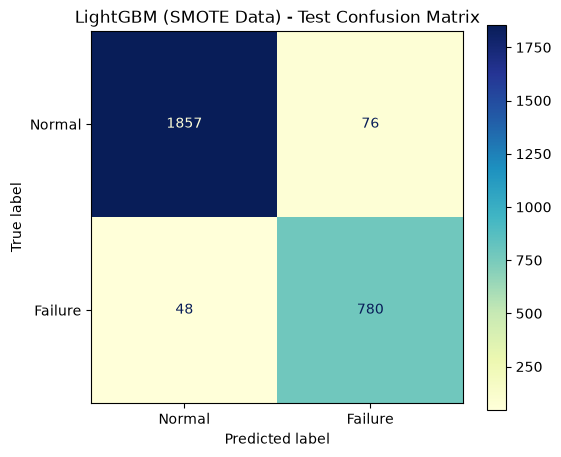

In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. SMOTE 데이터셋 로드
smote_csv_path = ROOT / 'smote_30_target_dataset.csv'
df_smote = pd.read_csv(smote_csv_path)
print(f"SMOTE 데이터셋 로드 완료! Shape: {df_smote.shape}")

# 식별자 및 불필요한 컬럼 제거 (존재할 경우)
drop_cols = [c for c in ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'] if c in df_smote.columns]
if drop_cols:
    df_smote = df_smote.drop(columns=drop_cols)

# 2. 피처(X)와 타깃(y) 분리
target_col = 'Machine failure'
X_smote = df_smote.drop(columns=[target_col])
y_smote = df_smote[target_col].astype(int)

# 범주형 변수 'Type' 원핫 인코딩
if 'Type' in X_smote.columns:
    X_smote = pd.get_dummies(X_smote, columns=['Type'], drop_first=False)

# LightGBM의 특수문자 제약 해결을 위해 피처 이름 변경 (JSON 특수 문자 및 괄호 제거)
# 안전하게 알파벳, 숫자, 언더바(_)만 남기고 공백은 언더바로 대체하는 방식을 채택합니다.
clean_cols = []
for col in X_smote.columns:
    # 대괄호, 중괄호, 쉼표, 콜론, 따옴표 등 이상 문자 제거
    c = col.replace('[', '').replace(']', '').replace('{', '').replace('}', '')
    c = c.replace(',', '').replace(':', '').replace('"', '').replace("'", "").replace('’', '')
    clean_cols.append(c)
X_smote.columns = clean_cols

# 3. 학습 및 테스트 데이터 분할
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_smote, y_smote, test_size=0.2, stratify=y_smote, random_state=RANDOM_STATE
)

# 4. LightGBM 모델 정의 및 학습
lgb_smote_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)
lgb_smote_model.fit(X_train_s, y_train_s)
print("SMOTE 데이터 적용 LightGBM 모델 학습 완료!")

# 5. 테스트 데이터 평가
y_pred_s = lgb_smote_model.predict(X_test_s)

print("\n=== [SMOTE LightGBM Test Evaluation Report] ===")
print(classification_report(y_test_s, y_pred_s, target_names=['Normal', 'Failure']))

# 6. 혼동 행렬 시각화
cm_s = confusion_matrix(y_test_s, y_pred_s)
plt.figure(figsize=(6, 5))
disp_s = ConfusionMatrixDisplay(confusion_matrix=cm_s, display_labels=['Normal', 'Failure'])
disp_s.plot(cmap='YlGnBu', ax=plt.gca())
plt.title('LightGBM (SMOTE Data) - Test Confusion Matrix')
plt.grid(False)
plt.show()


=== [LightGBM vs XGBoost 최종 테스트 데이터 성능 비교] ===


,Metric,Tuned LightGBM,XGBoost
0,Optimal Threshold,0.8300,0.9300
1,Precision (Failure),0.8305,0.9512
2,Recall (Failure),0.7206,0.5735
3,F1-Score (Failure),0.7717,0.7156
4,PR-AUC,0.8355,0.8160


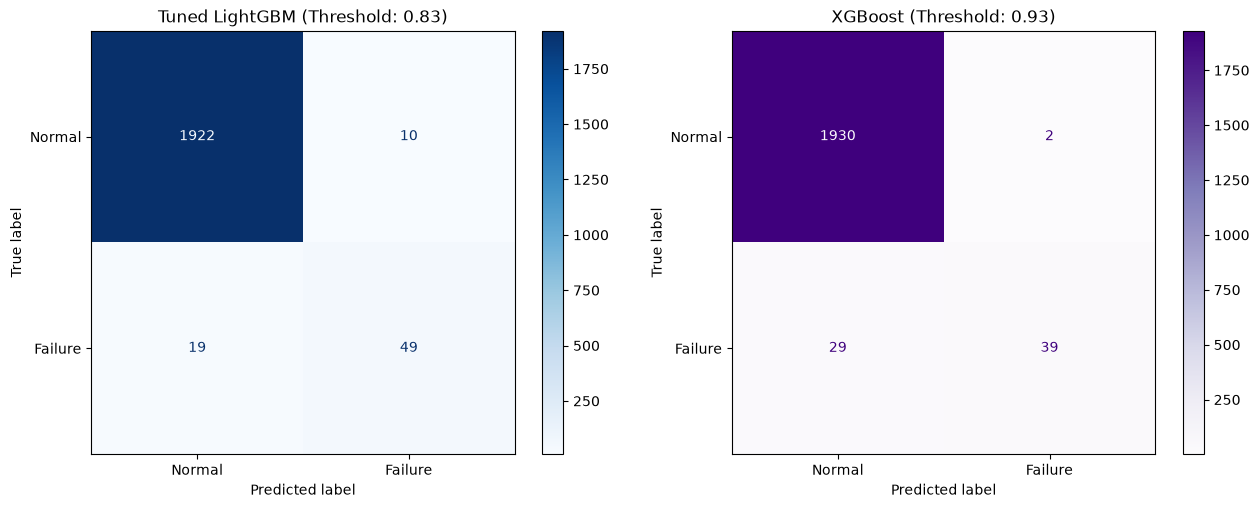

In [ ]:
# 6. LightGBM과 XGBoost 성능 비교 분석 데이터 프레임 구축

# 튜닝된 LightGBM 테스트 결과 획득 (이전 셀 변수 활용)
# tuned_test_preds, tuned_test_probs, best_t
lgb_precision = precision_score(y_test, tuned_test_preds, zero_division=0)
lgb_recall = recall_score(y_test, tuned_test_preds, zero_division=0)
lgb_f1 = f1_score(y_test, tuned_test_preds, zero_division=0)
lgb_pr_auc = average_precision_score(y_test, tuned_test_probs)

# XGBoost 테스트 결과 획득
xgb_precision = precision_score(y_test, xgb_test_preds, zero_division=0)
xgb_recall = recall_score(y_test, xgb_test_preds, zero_division=0)
xgb_f1 = f1_score(y_test, xgb_test_preds, zero_division=0)
xgb_pr_auc = average_precision_score(y_test, xgb_test_probs)

comparison_df = pd.DataFrame({
    'Metric': ['Optimal Threshold', 'Precision (Failure)', 'Recall (Failure)', 'F1-Score (Failure)', 'PR-AUC'],
    'Tuned LightGBM': [best_t, lgb_precision, lgb_recall, lgb_f1, lgb_pr_auc],
    'XGBoost': [best_xgb_t, xgb_precision, xgb_recall, xgb_f1, xgb_pr_auc]
})

print("\n=== [LightGBM vs XGBoost 최종 테스트 데이터 성능 비교] ===")
display(comparison_df.round(4))

# 7. 두 모델의 Confusion Matrix 나란히 시각화
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# LightGBM Confusion Matrix
cm_lgb = confusion_matrix(y_test, tuned_test_preds)
disp_lgb = ConfusionMatrixDisplay(confusion_matrix=cm_lgb, display_labels=['Normal', 'Failure'])
disp_lgb.plot(cmap='Blues', ax=axes[0])
axes[0].set_title(f'Tuned LightGBM (Threshold: {best_t:.2f})')
axes[0].grid(False)

# XGBoost Confusion Matrix
cm_xgb = confusion_matrix(y_test, xgb_test_preds)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['Normal', 'Failure'])
disp_xgb.plot(cmap='Purples', ax=axes[1])
axes[1].set_title(f'XGBoost (Threshold: {best_xgb_t:.2f})')
axes[1].grid(False)

plt.tight_layout()
plt.show()

=== [1] Deep Learning (MLP) 모델 학습 시작 ===
Deep Learning 모델 학습 완료!

=== [2] XGBoost 모델 학습 완료! ===
87/87 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

=== [3] SMOTE 데이터 기반 3대 모델 성능 비교 결과 ===


,Metric,Deep Learning (MLP),LightGBM,XGBoost
0,Precision (Failure),0.8618,0.9112,0.9156
1,Recall (Failure),0.9493,0.9420,0.9432
2,F1-Score (Failure),0.9034,0.9264,0.9292
3,PR-AUC,0.9720,0.9822,0.9820


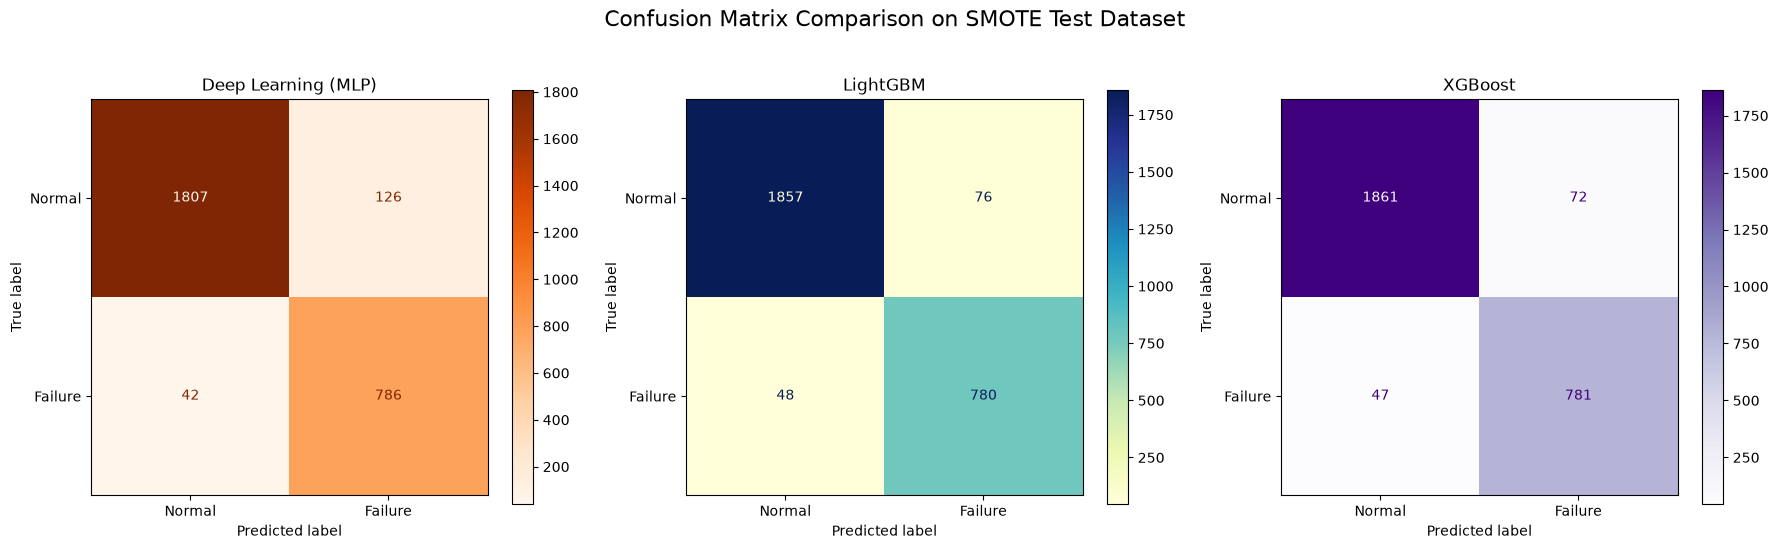

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import lightgbm as lgb
import xgboost as xgb
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score, average_precision_score

# 1. 데이터 준비 및 전처리 (X_train_s, X_test_s 활용)
scaler_s = StandardScaler()
X_train_scaled = scaler_s.fit_transform(X_train_s)
X_test_scaled = scaler_s.transform(X_test_s)

# 2. SMOTE 데이터용 Deep Learning (MLP) 모델 구축 및 학습
def build_smote_mlp(input_dim):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(16, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.1),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='pr_auc', curve='PR')]
    )
    return model

print("=== [1] Deep Learning (MLP) 모델 학습 시작 ===")
mlp_smote = build_smote_mlp(X_train_scaled.shape[1])

early_stop = callbacks.EarlyStopping(
    monitor='val_pr_auc',
    patience=10,
    mode='max',
    restore_best_weights=True
)

mlp_smote.fit(
    X_train_scaled, y_train_s,
    validation_split=0.15,
    epochs=50,
    batch_size=64,
    callbacks=[early_stop],
    verbose=0
)
print("Deep Learning 모델 학습 완료!")

# 3. XGBoost 모델 정의 및 학습 (SMOTE 균형 데이터이므로 scale_pos_weight 생략 가능)
xgb_smote_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    eval_metric='logloss'
)
xgb_smote_model.fit(X_train_s, y_train_s)
print("\n=== [2] XGBoost 모델 학습 완료! ===")

# 4. 모델 예측 결과 수집 (임계값 0.5 적용)
# Deep Learning
dl_probs = mlp_smote.predict(X_test_scaled).ravel()
dl_preds = (dl_probs >= 0.5).astype(int)

# LightGBM (이전 단계에서 학습된 lgb_smote_model 활용)
lgb_preds = lgb_smote_model.predict(X_test_s)
lgb_probs = lgb_smote_model.predict_proba(X_test_s)[:, 1]

# XGBoost
xgb_preds = xgb_smote_model.predict(X_test_s)
xgb_probs = xgb_smote_model.predict_proba(X_test_s)[:, 1]

# 5. 모델별 성능 평가지표 취합
results_summary = pd.DataFrame({
    'Metric': ['Precision (Failure)', 'Recall (Failure)', 'F1-Score (Failure)', 'PR-AUC'],
    'Deep Learning (MLP)': [
        precision_score(y_test_s, dl_preds),
        recall_score(y_test_s, dl_preds),
        f1_score(y_test_s, dl_preds),
        average_precision_score(y_test_s, dl_probs)
    ],
    'LightGBM': [
        precision_score(y_test_s, lgb_preds),
        recall_score(y_test_s, lgb_preds),
        f1_score(y_test_s, lgb_preds),
        average_precision_score(y_test_s, lgb_probs)
    ],
    'XGBoost': [
        precision_score(y_test_s, xgb_preds),
        recall_score(y_test_s, xgb_preds),
        f1_score(y_test_s, xgb_preds),
        average_precision_score(y_test_s, xgb_probs)
    ]
})

print("\n=== [3] SMOTE 데이터 기반 3대 모델 성능 비교 결과 ===")
display(results_summary.round(4))

# 6. Confusion Matrix 나란히 시각화
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Deep Learning CM
cm_dl = confusion_matrix(y_test_s, dl_preds)
disp_dl = ConfusionMatrixDisplay(confusion_matrix=cm_dl, display_labels=['Normal', 'Failure'])
disp_dl.plot(cmap='Oranges', ax=axes[0])
axes[0].set_title('Deep Learning (MLP)')
axes[0].grid(False)

# LightGBM CM
cm_lgb = confusion_matrix(y_test_s, lgb_preds)
disp_lgb = ConfusionMatrixDisplay(confusion_matrix=cm_lgb, display_labels=['Normal', 'Failure'])
disp_lgb.plot(cmap='YlGnBu', ax=axes[1])
axes[1].set_title('LightGBM')
axes[1].grid(False)

# XGBoost CM
cm_xgb_s = confusion_matrix(y_test_s, xgb_preds)
disp_xgb_s = ConfusionMatrixDisplay(confusion_matrix=cm_xgb_s, display_labels=['Normal', 'Failure'])
disp_xgb_s.plot(cmap='Purples', ax=axes[2])
axes[2].set_title('XGBoost')
axes[2].grid(False)

plt.suptitle('Confusion Matrix Comparison on SMOTE Test Dataset', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

## Module 6 (Slides 21–24) · 최종 성능 평가 및 설명 가능성

혼동행렬, Precision, Recall, F1, PR-AUC를 **봉인된 테스트 분할**에서 한 번 계산합니다. Feature Importance는 인과적 고장 원인의 증거가 아닙니다.

,model,threshold,Precision,Recall,F1,PR_AUC,TP,TN,FP,FN
0,RandomForest,0.67,0.6353,0.7941,0.7059,0.5969,54,1901,31,14


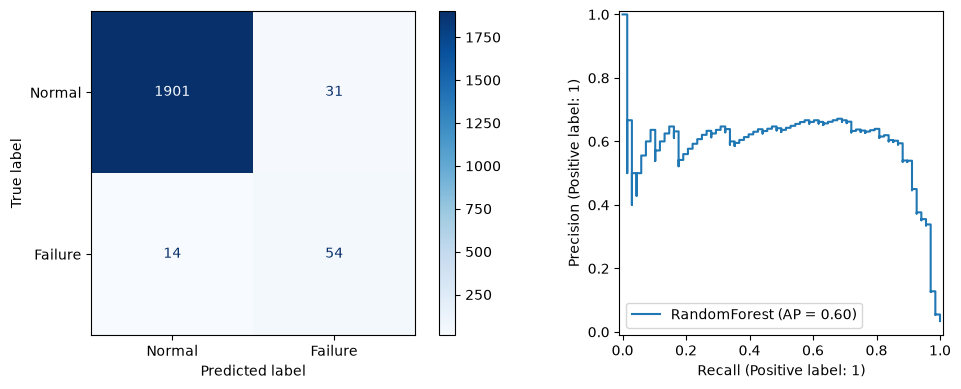

241

In [ ]:
test_prob=chosen_model.predict_proba(X_test)[:,1]
test_pred=(test_prob>=chosen_threshold).astype(int)
metrics = {'model':chosen_name,'threshold':float(chosen_threshold),
           'Precision':float(precision_score(y_test,test_pred,zero_division=0)),
           'Recall':float(recall_score(y_test,test_pred,zero_division=0)),
           'F1':float(f1_score(y_test,test_pred,zero_division=0)),
           'PR_AUC':float(average_precision_score(y_test,test_prob)),
           'TP':int(((y_test==1)&(test_pred==1)).sum()),
           'TN':int(((y_test==0)&(test_pred==0)).sum()),
           'FP':int(((y_test==0)&(test_pred==1)).sum()),
           'FN':int(((y_test==1)&(test_pred==0)).sum())}
display(pd.DataFrame([metrics]).round(4))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['Normal','Failure'],ax=ax[0],cmap='Blues')
PrecisionRecallDisplay.from_predictions(y_test,test_prob,ax=ax[1],name=chosen_name)
plt.tight_layout();plt.show()
(ROOT/'test_metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')

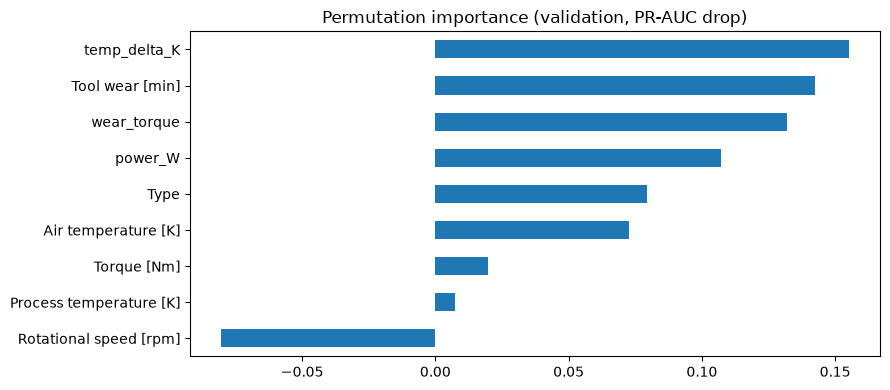

,importance
temp_delta_K,0.15505
Tool wear [min],0.14260
wear_torque,0.13202
power_W,0.10710
Type,0.07945
Air temperature [K],0.07266
Torque [Nm],0.01992
Process temperature [K],0.00723
Rotational speed [rpm],-0.08034


In [ ]:
# permutation_importance: 테스트 분할은 앞에서 1회 성능 보고에 사용하였으므로,
# 설명 예시는 검증셋에 대해 계산합니다.
explain_x=X_val.sample(n=min(300,len(X_val)),random_state=RANDOM_STATE)
explain_y=y_val.loc[explain_x.index]
pi = permutation_importance(chosen_model,explain_x,explain_y,scoring='average_precision',
                            n_repeats=2,random_state=RANDOM_STATE,n_jobs=1)
imp=pd.Series(pi.importances_mean,index=FEATURES).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(9,4));imp.sort_values().plot.barh(ax=ax)
ax.set_title('Permutation importance (validation, PR-AUC drop)')
plt.tight_layout();plt.show()
display(imp.to_frame('importance').round(5))

In [ ]:
## Seed 값을 고

## Module 7 (Slides 25–28) · 대시보드와 Human-in-the-loop

**교육용 오프라인 모니터링 대시보드**를 HTML로 저장합니다. UCI에는 동일 설비의 실제 시간 정보가 없으므로 아래 샘플들은 **서로 다른 관측치**로 표시합니다. 실제 센서의 실시간 추세로 해석하면 안 됩니다.

In [ ]:
# 모델이 보지 않은 테스트 관측치에 대한 위험 점수 사용
monitor=X_test.copy()
monitor['actual_failure']=y_test.to_numpy()
monitor['failure_probability']=test_prob
monitor['prediction']=(test_prob>=chosen_threshold).astype(int)
monitor['recommendation']=np.where(monitor['prediction']==1,
    'Operator review / inspection recommended','Continue monitoring')
monitor=monitor.sort_values('failure_probability',ascending=False)
display(monitor.head(12))
fig = px.scatter(monitor.reset_index(drop=True),x='Rotational speed [rpm]',
                 y='Torque [Nm]',color='failure_probability',
                 hover_data=['Type','Tool wear [min]','actual_failure'],
                 title='AI4I Test Records — Predicted Failure Risk (not a time series)',
                 color_continuous_scale='Turbo')
fig.update_layout(width=920,height=520)
fig.show()
html_path=ROOT/'monitoring_dashboard.html'
fig.write_html(str(html_path),include_plotlyjs=True)
print('대시보드 HTML 저장:',html_path)

In [ ]:
# 모의 작업자 판단 로그: 승인 상태는 실습 시 수동 결정하며, 설비를 자동제어하지 않음
review=monitor.head(10).copy().reset_index(drop=True)
review.insert(0,'review_id',[f'REV-{i+1:03d}' for i in range(len(review))])
review['operator_decision']='PENDING_REVIEW'
review['operator_note']=''
cols=['review_id','failure_probability','prediction','recommendation',
      'operator_decision','operator_note']
display(review[cols])
review[cols].to_csv(ROOT/'operator_review_template.csv',index=False,encoding='utf-8-sig')
print('점검 후 담당자가 결정/기록하는 양식을 저장했습니다.')

NameError: name 'monitor' is not defined

## Module 8 (Slides 29–32) · 팀별 통합 프로젝트 및 산출물 다운로드

**소형 냉각팬 P01~P06와의 연결:** AI4I는 P04 검사대가 실제로 수집한 기록이 아니라 회전설비 상태 분석을 위한 **가상 교육용 매핑**입니다. 직접적인 실제 효과(정지시간 감소, ROI, 조기 경보 시간)는 이 데이터만으로 입증할 수 없습니다.

팀 발표 질문:
1. 어떤 특성이 고장 레이블과 관련되는가?
2. 물리적 규칙과 머신러닝은 어떤 부분이 다른가?
3. FP/FN은 공장 운영에 어떤 영향을 주는가?
4. 점검 권고 이후 누가 무엇을 판단하는가?
5. 실제 P04 적용을 위해 어떤 추가 현장 정보가 필요한가?

In [ ]:
from zipfile import ZipFile
# 학습 데이터/모델과 평가 산출물 저장. 원본 데이터의 라이선스 표시
joblib.dump(chosen_model, ROOT/'chosen_failure_classifier.joblib')
summary = {
  'dataset':'UCI AI4I 2020, ID 601, CC BY 4.0, DOI 10.24432/C5HS5C',
  'method':'snapshot machine-failure classification, no RUL, no predictive lead time',
  'split':'stratified 60/20/20 (train/validation/test)',
  'selected_model':chosen_name,
  'test_metrics':metrics,
  'limitations':['synthetic dataset','not fan factory sensor records',
                 'no physical asset-specific continuous timestamp',
                 'educational warning thresholds are not safety limits']
}
(ROOT/'experiment_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
zip_path=ROOT/'ai4i_lab_outputs.zip'
with ZipFile(zip_path,'w') as z:
    for f in ROOT.iterdir():
        if f.is_file() and f!=zip_path:
            z.write(f,f.name)
print('산출물 ZIP:',zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Colab이 아니라면 위 경로에서 ZIP 파일을 확인하세요.')

NameError: name 'joblib' is not defined

### 평가 루브릭 (100점)

| 항목 | 배점 |
|---|---:|
| 데이터 구조 이해 | 15 |
| EDA 및 시각화 | 15 |
| 고장 메커니즘 분석 | 15 |
| 규칙 기반 이상탐지 | 15 |
| ML 모델 구현 | 15 |
| 오탐·미탐 및 설명 가능성 | 10 |
| 모니터링·조치 권고 | 10 |
| 결과 발표 및 한계 기술 | 5 |

**최종 제출:** `.ipynb` 실행 결과 + `ai4i_lab_outputs.zip` + 5분 발표. 모델 고장 분류를 진정한 미래 고장 예측이나 현장 성능 검증으로 표현하지 않습니다.